# Quick Commerce Delivery Analysis - EDA

Dataset: 100,000 orders from Blinkit, Swiggy Instamart and JioMart (Jul - Sep 2026).

I already wrote the SQL queries for this project in `Delivery_Analysis.sql`. Here I redo those numbers in pandas to cross-check them, and then look a bit deeper at timing, delays, feedback and customers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Loading the data

In [2]:
df = pd.read_csv("ecommerce_delivery_analytics_cleaned.csv")
print(df.shape)
df.head()

(100000, 13)


,Order ID,Customer ID,Platform,Order Timestamp,Order Date,Order Hour,Delivery Time (Minutes),Product Category,Order Value (INR),Customer Feedback,Service Rating,Delivery Delay,Refund Requested
0,ORD000001,CUST2824,JioMart,2026-08-04 16:19:07,2026-08-04,16,30,Fruits & Vegetables,382,"Fast delivery, great service!",5,No,No
1,ORD000002,CUST1409,Blinkit,2026-09-26 15:54:40,2026-09-26,15,16,Dairy,279,Quick and reliable!,5,No,No
2,ORD000003,CUST5506,JioMart,2026-09-06 12:21:53,2026-09-06,12,25,Beverages,599,Items missing from order.,2,No,Yes
3,ORD000004,CUST5012,JioMart,2026-08-24 14:19:09,2026-08-24,14,42,Beverages,946,Items missing from order.,2,Yes,Yes
4,ORD000005,CUST4657,Blinkit,2026-07-15 12:49:10,2026-07-15,12,30,Beverages,334,"Fast delivery, great service!",5,No,No


In [3]:
# same column names as the SQL table
df.columns = ["order_id", "customer_id", "platform", "order_timestamp", "order_date", "order_hour",
              "delivery_time_min", "product_category", "order_value_inr", "customer_feedback",
              "service_rating", "delivery_delay", "refund_requested"]

df["order_timestamp"] = pd.to_datetime(df["order_timestamp"])
df["order_date"] = pd.to_datetime(df["order_date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   order_id           100000 non-null  str           
 1   customer_id        100000 non-null  str           
 2   platform           100000 non-null  str           
 3   order_timestamp    100000 non-null  datetime64[us]
 4   order_date         100000 non-null  datetime64[us]
 5   order_hour         100000 non-null  int64         
 6   delivery_time_min  100000 non-null  int64         
 7   product_category   100000 non-null  str           
 8   order_value_inr    100000 non-null  int64         
 9   customer_feedback  100000 non-null  str           
 10  service_rating     100000 non-null  int64         
 11  delivery_delay     100000 non-null  str           
 12  refund_requested   100000 non-null  str           
dtypes: datetime64[us](2), int64(4), str(7)
memory usage: 9.9

## Data checks

In [4]:
print(df.isnull().sum())
print()
print("duplicate rows:", df.duplicated().sum())
print("duplicate order ids:", df["order_id"].duplicated().sum())
print("dates:", df["order_date"].min().date(), "to", df["order_date"].max().date())

order_id             0
customer_id          0
platform             0
order_timestamp      0
order_date           0
order_hour           0
delivery_time_min    0
product_category     0
order_value_inr      0
customer_feedback    0
service_rating       0
delivery_delay       0
refund_requested     0
dtype: int64



duplicate rows: 0
duplicate order ids: 0
dates: 2026-07-01 to 2026-09-30


In [5]:
df[["order_hour", "delivery_time_min", "order_value_inr", "service_rating"]].describe()

,order_hour,delivery_time_min,order_value_inr,service_rating
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,14.185430,29.536140,590.994400,3.240790
std,5.504633,9.958933,417.409058,1.575962
min,0.000000,5.000000,50.000000,1.000000
25%,10.000000,23.000000,283.000000,2.000000
50%,14.000000,30.000000,481.000000,3.000000
75%,19.000000,36.000000,770.000000,5.000000
max,23.000000,76.000000,2000.000000,5.000000


No nulls and no duplicates, which makes sense since this is the already cleaned file. Delivery time goes from 5 to 76 minutes and order value from 50 to 2000, nothing that looks wrong.

Before going further I want to see how `delivery_delay` and `refund_requested` were decided, because they might just be rules on top of other columns.

In [6]:
print(df.groupby("delivery_delay")["delivery_time_min"].agg(["min", "max", "mean"]))
print()
print(df.groupby("service_rating")["refund_requested"].apply(lambda x: (x == "Yes").mean()))

                min  max       mean
delivery_delay                     
No                5   40  26.998957
Yes              41   76  45.556466

service_rating
1    1.0
2    1.0
3    0.0
4    0.0
5    0.0
Name: refund_requested, dtype: float64


So a delay is anything over 40 minutes, and a refund is always requested when the rating is 1 or 2 (and never for 3 to 5). Both flags follow directly from other columns, so I need to keep that in mind when reading the delay and refund results later.

In [7]:
# helper columns used in the rest of the notebook
df["delayed"] = (df["delivery_delay"] == "Yes").astype(int)
df["refund"] = (df["refund_requested"] == "Yes").astype(int)
df["weekday"] = df["order_timestamp"].dt.day_name()

## Overall numbers

In [8]:
print("total orders      :", len(df))
print("unique customers  :", df["customer_id"].nunique())
print("total revenue     :", df["order_value_inr"].sum())
print("avg order value   :", round(df["order_value_inr"].mean(), 2))
print("avg delivery time :", round(df["delivery_time_min"].mean(), 2), "min")
print("delay rate        :", round(df["delayed"].mean() * 100, 2), "%")
print("refund rate       :", round(df["refund"].mean() * 100, 2), "%")
print("avg rating        :", round(df["service_rating"].mean(), 2))

total orders      : 100000
unique customers  : 9000
total revenue     : 59099440
avg order value   : 590.99
avg delivery time : 29.54 min
delay rate        : 13.67 %
refund rate       : 45.82 %
avg rating        : 3.24


Around 13.7% of orders are late and almost 46% ask for a refund. The refund number is very high and I come back to it in the feedback section.

## Platforms

In [9]:
platform = df.groupby("platform").agg(
    orders=("order_id", "count"),
    revenue=("order_value_inr", "sum"),
    avg_order_value=("order_value_inr", "mean"),
    avg_delivery_min=("delivery_time_min", "mean"),
    delay_rate=("delayed", "mean"),
    refund_rate=("refund", "mean"),
    avg_rating=("service_rating", "mean"),
)
platform["order_share_pct"] = platform["orders"] / platform["orders"].sum() * 100
platform["revenue_share_pct"] = platform["revenue"] / platform["revenue"].sum() * 100
platform["delay_rate"] = platform["delay_rate"] * 100
platform["refund_rate"] = platform["refund_rate"] * 100
platform.round(2)

,orders,revenue,avg_order_value,avg_delivery_min,delay_rate,refund_rate,avg_rating,order_share_pct,revenue_share_pct
platform,,,,,,,,,
Blinkit,33424,19705084,589.55,29.47,13.38,45.93,3.23,33.42,33.34
JioMart,33127,19562372,590.53,29.63,13.83,45.82,3.25,33.13,33.10
Swiggy Instamart,33449,19831984,592.90,29.50,13.81,45.71,3.24,33.45,33.56


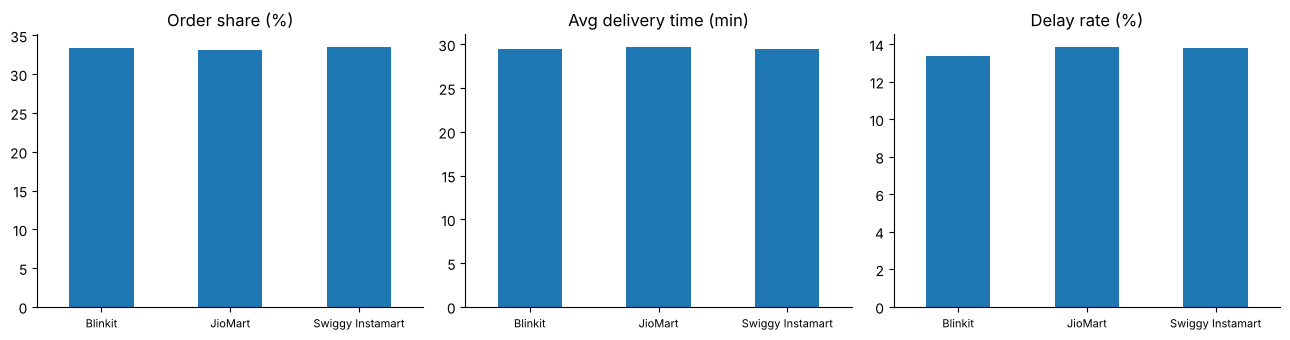

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

platform["order_share_pct"].plot(kind="bar", ax=axes[0], title="Order share (%)", rot=0)
platform["avg_delivery_min"].plot(kind="bar", ax=axes[1], title="Avg delivery time (min)", rot=0)
platform["delay_rate"].plot(kind="bar", ax=axes[2], title="Delay rate (%)", rot=0)

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

The three platforms look almost the same. Each has about a third of the orders, delivery time is around 29.5 minutes for all of them and the delay rate only ranges from 13.4% to 13.8%. Blinkit is slightly better on delays but the difference is tiny. I can't say any platform is clearly better from this data.

## Product categories

In [11]:
category = df.groupby("product_category").agg(
    orders=("order_id", "count"),
    revenue=("order_value_inr", "sum"),
    avg_order_value=("order_value_inr", "mean"),
    delay_rate=("delayed", "mean"),
)
category["revenue_share_pct"] = category["revenue"] / category["revenue"].sum() * 100
category["delay_rate"] = category["delay_rate"] * 100
category = category.sort_values("revenue", ascending=False)
category.round(2)

,orders,revenue,avg_order_value,delay_rate,revenue_share_pct
product_category,,,,,
Personal Care,16533,17395601,1052.17,13.63,29.43
Grocery,16737,14194055,848.06,13.82,24.02
Beverages,16536,9086669,549.51,13.52,15.38
Dairy,16857,7610522,451.48,13.72,12.88
Fruits & Vegetables,16632,6246517,375.57,13.77,10.57
Snacks,16705,4566076,273.34,13.57,7.73


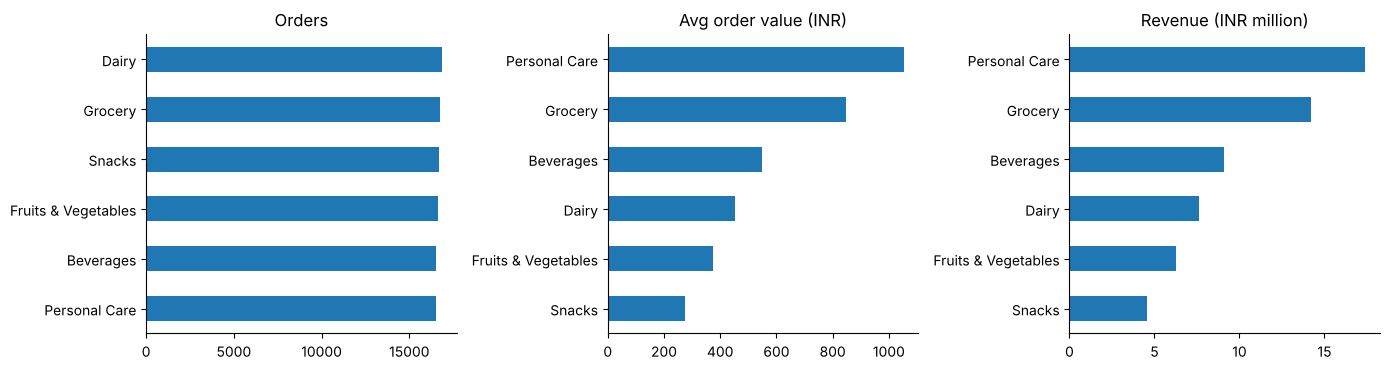

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

category["orders"].sort_values().plot(kind="barh", ax=axes[0], title="Orders")
category["avg_order_value"].sort_values().plot(kind="barh", ax=axes[1], title="Avg order value (INR)")
(category["revenue"] / 1e6).sort_values().plot(kind="barh", ax=axes[2], title="Revenue (INR million)")

for ax in axes:
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Orders are spread almost equally over the six categories (about 16.5k to 16.9k each), so the revenue difference comes only from the basket size. Personal Care (avg about 1052) and Grocery (about 848) bring in a bit more than half of the total revenue, and Snacks is the lowest with an average order of only about 273. Delay rate is the same for every category.

## Delivery time and delays

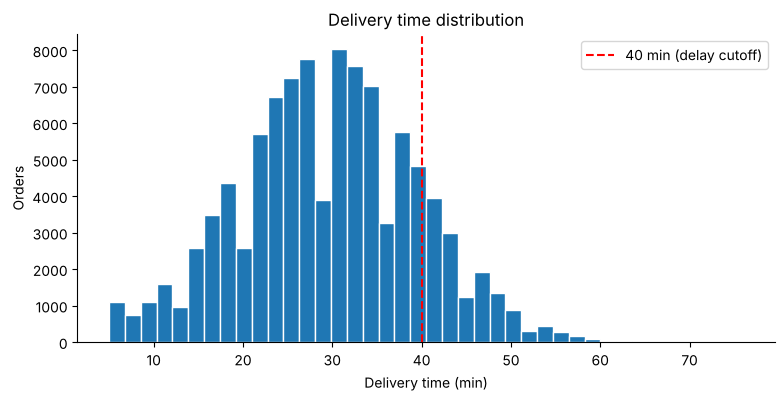

0.50    30.0
0.75    36.0
0.90    42.0
0.95    46.0
0.99    53.0
Name: delivery_time_min, dtype: float64


In [13]:
plt.hist(df["delivery_time_min"], bins=40, edgecolor="white")
plt.axvline(40, color="red", linestyle="--", label="40 min (delay cutoff)")
plt.xlabel("Delivery time (min)")
plt.ylabel("Orders")
plt.title("Delivery time distribution")
plt.legend()
plt.show()

print(df["delivery_time_min"].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

Most deliveries are around 30 minutes (median 30, 90th percentile about 42). The late orders average about 45.6 minutes and the longest one took 76.

## When do people order?

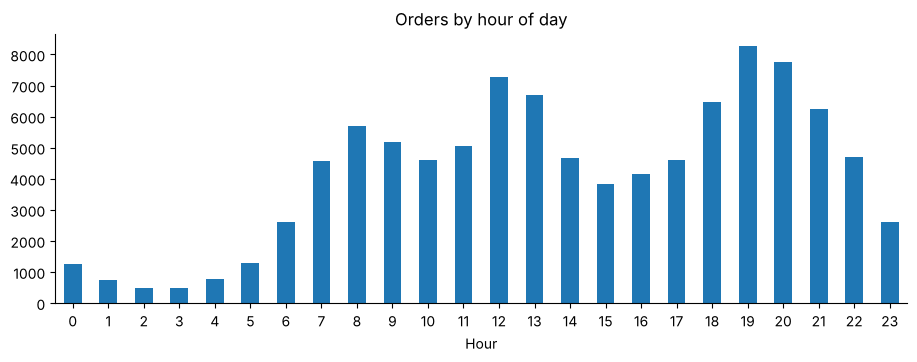

order_hour
19    8259
20    7767
12    7266
13    6683
18    6482
Name: orders, dtype: int64


In [14]:
hourly = df.groupby("order_hour").agg(
    orders=("order_id", "count"),
    avg_delivery=("delivery_time_min", "mean"),
    delay_rate=("delayed", "mean"),
)

hourly["orders"].plot(kind="bar", figsize=(11, 3.5), title="Orders by hour of day", rot=0)
plt.xlabel("Hour")
plt.show()

print(hourly["orders"].sort_values(ascending=False).head(5))

In [15]:
# does a busy hour mean slower delivery?
print(hourly[["orders", "avg_delivery", "delay_rate"]].corr().round(2))
print()
print("avg delivery time range across hours:", hourly["avg_delivery"].min().round(1), "-", hourly["avg_delivery"].max().round(1))
print("delay rate range across hours:", (hourly["delay_rate"].min() * 100).round(1), "-", (hourly["delay_rate"].max() * 100).round(1))

              orders  avg_delivery  delay_rate
orders          1.00          0.15       -0.05
avg_delivery    0.15          1.00        0.48
delay_rate     -0.05          0.48        1.00

avg delivery time range across hours: 28.8 - 29.9
delay rate range across hours: 12.5 - 15.8


weekday
Monday        956.0
Tuesday       967.0
Wednesday     953.0
Thursday      975.0
Friday       1262.0
Saturday     1254.0
Sunday       1250.0
Name: orders, dtype: float64


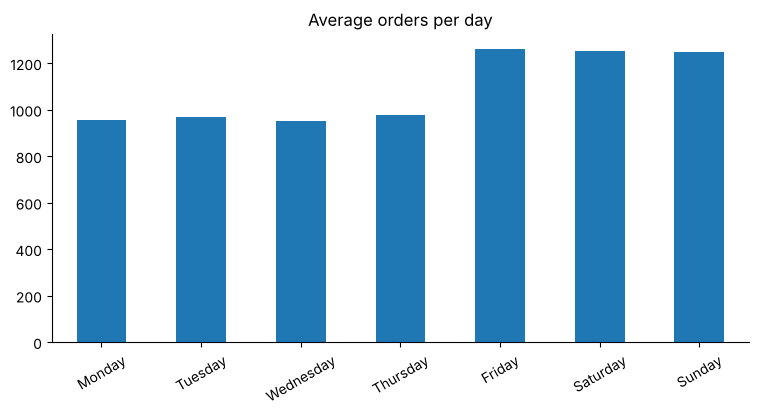

Fri-Sun vs Mon-Thu: 1255 vs 963 orders a day, 30 % higher


In [16]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily = df.groupby(["order_date", "weekday"]).size().reset_index(name="orders")
by_day = daily.groupby("weekday")["orders"].mean().reindex(days)
print(by_day.round(0))

by_day.plot(kind="bar", title="Average orders per day", rot=30)
plt.xlabel("")
plt.show()

fri_sun = daily[daily["weekday"].isin(["Friday", "Saturday", "Sunday"])]["orders"].mean()
mon_thu = daily[~daily["weekday"].isin(["Friday", "Saturday", "Sunday"])]["orders"].mean()
print("Fri-Sun vs Mon-Thu:", round(fri_sun), "vs", round(mon_thu), "orders a day,", round((fri_sun / mon_thu - 1) * 100), "% higher")

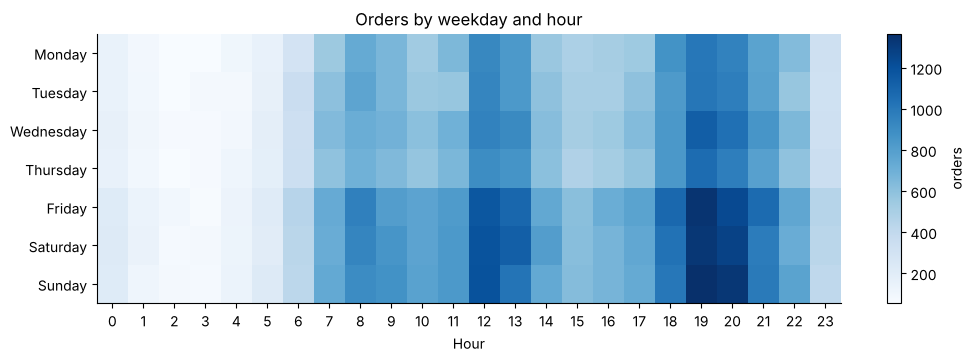

In [17]:
heat = df.pivot_table(index="weekday", columns="order_hour", values="order_id", aggfunc="count").reindex(days)

plt.figure(figsize=(12, 3.5))
plt.imshow(heat, aspect="auto", cmap="Blues")
plt.colorbar(label="orders")
plt.yticks(range(7), days)
plt.xticks(range(24))
plt.xlabel("Hour")
plt.title("Orders by weekday and hour")
plt.show()

There are two clear peaks, lunch (12-13) and evening (19-20), and a smaller bump around 8-9 in the morning. Between 1 and 4 at night there are hardly any orders. Friday to Sunday are about 30% busier than the rest of the week.

The surprising part is that busy hours are not slower. Average delivery time stays between about 28.8 and 29.9 minutes and the delay rate stays between about 12.5% and 15.8% in every hour, so peak time does not seem to affect delivery speed here.

## Ratings, feedback and refunds

In [18]:
delay_effect = df.groupby("delivery_delay").agg(
    orders=("order_id", "count"),
    avg_rating=("service_rating", "mean"),
    refund_rate=("refund", "mean"),
)
delay_effect["refund_rate"] = delay_effect["refund_rate"] * 100
delay_effect.round(2)

,orders,avg_rating,refund_rate
delivery_delay,,,
No,86328,3.24,45.78
Yes,13672,3.23,46.06


I expected delayed orders to have worse ratings and more refunds, but they are basically the same as on-time orders (rating about 3.24 and refund rate about 46% in both). In this data a late delivery doesn't make customers any less happy.

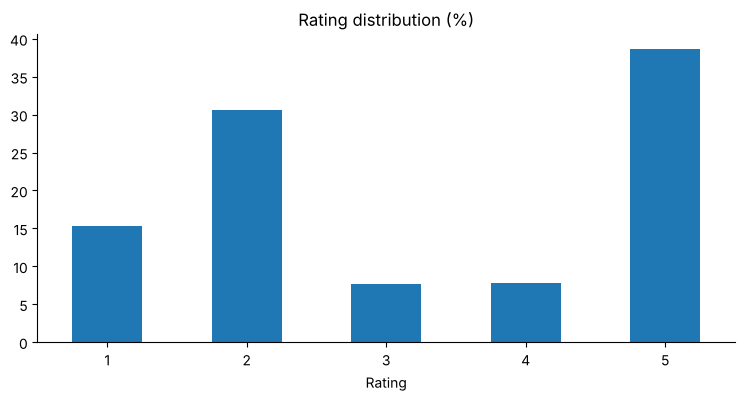

In [19]:
(df["service_rating"].value_counts(normalize=True).sort_index() * 100).plot(
    kind="bar", title="Rating distribution (%)", rot=0)
plt.xlabel("Rating")
plt.show()

In [20]:
feedback = df.groupby("customer_feedback").agg(
    count=("order_id", "count"),
    avg_rating=("service_rating", "mean"),
    refund_rate=("refund", "mean"),
    delay_rate=("delayed", "mean"),
).sort_values("avg_rating")
feedback[["refund_rate", "delay_rate"]] = (feedback[["refund_rate", "delay_rate"]] * 100).round(1)
feedback

,count,avg_rating,refund_rate,delay_rate
customer_feedback,,,,
"Horrible experience, never ordering again.",7529,1.0,100.0,13.7
Wrong item delivered.,7738,1.0,100.0,13.9
Items missing from order.,7737,2.0,100.0,14.5
Delivery person was rude.,7643,2.0,100.0,13.5
"Very late delivery, not happy.",7592,2.0,100.0,13.8
"Not fresh, disappointed.",7580,2.0,100.0,13.2
Packaging could be better.,7704,3.0,0.0,13.8
Good quality products.,7789,4.0,0.0,13.9
Excellent experience!,7784,5.0,0.0,13.2


Ratings are either very good or very bad, with few 3s and 4s. The six negative comments (rude delivery person, wrong item, missing items, not fresh, very late delivery, horrible experience) all have a rating of 1-2 and a 100% refund rate, and together they make up the 46% refunds.

Only one of the six is about delivery speed. The others are about wrong or missing items, freshness and the rider's behaviour, so most refund problems come from order quality and service, not from lateness. Also, the delay rate is the same for every feedback type, even for "Very late delivery, not happy", which seems odd.

## Customers

In [21]:
cust = df.groupby("customer_id").agg(
    orders=("order_id", "count"),
    spend=("order_value_inr", "sum"),
)
print(cust.describe().round(1))

       orders    spend
count  9000.0   9000.0
mean     11.1   6566.6
std       3.3   2388.8
min       2.0    671.0
25%       9.0   4840.0
50%      11.0   6378.0
75%      13.0   8152.0
max      26.0  16255.0


top 20% of customers give 30.8 % of revenue
customers with only 1 order: 0


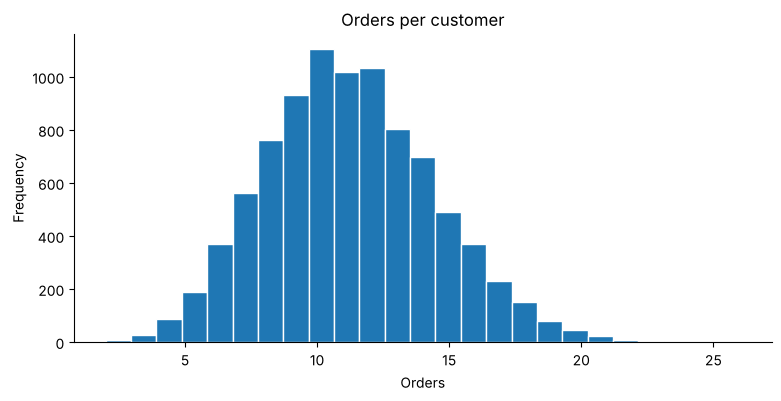

In [22]:
spend = cust["spend"].sort_values(ascending=False)
top20 = spend.head(int(len(spend) * 0.2)).sum() / spend.sum() * 100
print("top 20% of customers give", round(top20, 1), "% of revenue")
print("customers with only 1 order:", (cust["orders"] == 1).sum())

cust["orders"].plot(kind="hist", bins=25, edgecolor="white", title="Orders per customer")
plt.xlabel("Orders")
plt.show()

In [23]:
# top 10 orders by value (same as the SQL query)
df.sort_values("order_value_inr", ascending=False).head(10)[
    ["order_id", "customer_id", "platform", "product_category", "order_value_inr", "delivery_time_min"]]

,order_id,customer_id,platform,product_category,order_value_inr,delivery_time_min
79519,ORD079520,CUST8057,Blinkit,Personal Care,2000,37
70417,ORD070418,CUST3057,JioMart,Personal Care,2000,36
2709,ORD002710,CUST6302,JioMart,Personal Care,2000,18
58473,ORD058474,CUST4621,Blinkit,Personal Care,2000,34
68551,ORD068552,CUST8187,JioMart,Personal Care,2000,33
98210,ORD098211,CUST5408,JioMart,Personal Care,2000,44
21023,ORD021024,CUST9108,Swiggy Instamart,Personal Care,2000,16
69389,ORD069390,CUST8010,JioMart,Personal Care,2000,20
12683,ORD012684,CUST3486,Swiggy Instamart,Personal Care,2000,11
35623,ORD035624,CUST9682,Swiggy Instamart,Personal Care,2000,41


There are 9,000 customers with about 11 orders each in the three months and nobody ordered only once. The top 20% of customers give about 31% of revenue, so it's fairly spread out and there is no small group of customers carrying the business.

## Correlation

In [24]:
df[["order_hour", "delivery_time_min", "order_value_inr", "service_rating", "delayed", "refund"]].corr().round(2)

,order_hour,delivery_time_min,order_value_inr,service_rating,delayed,refund
order_hour,1.0,-0.00,0.00,-0.00,-0.00,-0.00
delivery_time_min,-0.0,1.00,0.01,0.00,0.64,0.00
order_value_inr,0.0,0.01,1.00,-0.00,0.00,0.00
service_rating,-0.0,0.00,-0.00,1.00,-0.00,-0.92
delayed,-0.0,0.64,0.00,-0.00,1.00,0.00
refund,-0.0,0.00,0.00,-0.92,0.00,1.00


Apart from the built-in relationships (delivery time with delay, and rating with refund) nothing is correlated. Order value, hour, delivery time and rating are all close to 0 with each other.

## Summary

- The data is clean: 100,000 rows, no nulls, no duplicates.
- All three platforms perform about the same (share, delivery time, delay rate and rating), so there is no clear winner.
- Revenue depends on basket size. Personal Care and Grocery are a bit over half of the revenue, Snacks is the weakest.
- Orders peak at lunch and in the evening, and Friday to Sunday are about 30% higher than weekdays.
- Delivery stays just as fast in busy hours.
- About 13.7% of orders take more than 40 minutes.
- About 46% of orders end in a refund request, which is very high. They come from low ratings, and most of the bad feedback is about wrong or missing items, freshness and rider behaviour.
- Late deliveries don't get lower ratings or more refunds than on-time ones.

What I would suggest from this: work on order accuracy (wrong and missing items), product freshness and rider behaviour first, since those drive the refunds; push bundles for the low-value categories; and plan staff for the lunch and evening peaks and the weekends.

